# Comedy Show: learn decisions with a tree


## 1 · Import the tools


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

## 2 · Load and inspect the table


In [19]:
df = pd.read_csv("data.csv")
df

,Age,Experience,Rank,Nationality,Go
0,36,10,9,UK,NO
1,42,12,4,USA,NO
2,23,4,6,N,NO
3,52,4,4,USA,NO
4,43,21,8,USA,YES
5,44,14,5,UK,NO
6,66,3,7,N,YES
7,35,14,9,UK,YES
8,52,13,7,N,YES
9,35,5,9,N,YES


## 3 · Convert categories into numbers


In [20]:
d = {'UK': 0, 'USA': 1, 'N': 2}
df['Nationality'] = df['Nationality'].map(d)
d = {'YES': 1, 'NO': 0}
df['Go'] = df['Go'].map(d)

df

,Age,Experience,Rank,Nationality,Go
0,36,10,9,0,0
1,42,12,4,1,0
2,23,4,6,2,0
3,52,4,4,1,0
4,43,21,8,1,1
5,44,14,5,0,0
6,66,3,7,2,1
7,35,14,9,0,1
8,52,13,7,2,1
9,35,5,9,2,1


## 4 · Choose features and target


In [21]:
features = ['Age', 'Experience', 'Rank', 'Nationality']

X = df[features]
y = df['Go']

display(X)
display(y)

,Age,Experience,Rank,Nationality
0,36,10,9,0
1,42,12,4,1
2,23,4,6,2
3,52,4,4,1
4,43,21,8,1
5,44,14,5,0
6,66,3,7,2
7,35,14,9,0
8,52,13,7,2
9,35,5,9,2


0     0
1     0
2     0
3     0
4     1
5     0
6     1
7     1
8     1
9     1
10    0
11    1
12    1
Name: Go, dtype: int64

## 5 · Train and visualize the Decision Tree


[Text(0.4, 0.9, 'Rank <= 6.5\ngini = 0.497\nsamples = 13\nvalue = [6, 7]'),
 Text(0.2, 0.7, 'gini = 0.0\nsamples = 5\nvalue = [5, 0]'),
 Text(0.30000000000000004, 0.8, 'True  '),
 Text(0.6, 0.7, 'Nationality <= 0.5\ngini = 0.219\nsamples = 8\nvalue = [1, 7]'),
 Text(0.5, 0.8, '  False'),
 Text(0.4, 0.5, 'Experience <= 9.5\ngini = 0.375\nsamples = 4\nvalue = [1, 3]'),
 Text(0.2, 0.3, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.6, 0.3, 'Experience <= 12.0\ngini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.4, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.8, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.8, 0.5, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]')]

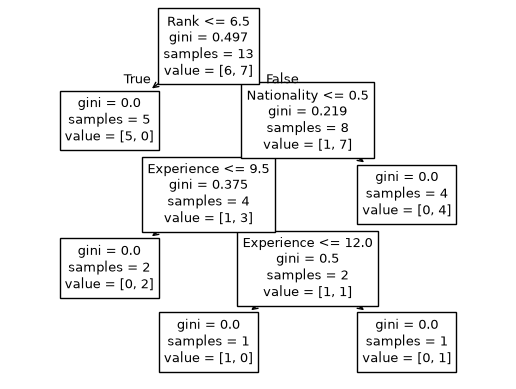

In [34]:
dtree = DecisionTreeClassifier()
dtree = dtree.fit(X, y)

tree.plot_tree(dtree, feature_names=features)

In [35]:
importances = dtree.feature_importances_
importances

array([0.        , 0.23214286, 0.72916667, 0.03869048])

## 6 · Predict

In [ ]:
sample = pd.DataFrame([{
    'Age': 40,
    'Experience': 10,
    'Rank': 7,
    'Nationality': 1,
}])

print(dtree.predict(sample))

# Assignment 1

## Part A 

In [29]:
import sdv

metadata = sdv.metadata.Metadata.detect_from_dataframes(data={'comedian': df})
synthesizer = sdv.single_table.GaussianCopulaSynthesizer(metadata)
synthesizer.fit({'comedian': df})
synthetic_data = synthesizer.sample(num_rows=100)['comedian']
df_augmented = pd.concat([df, synthetic_data],ignore_index=True)
display(df_augmented)

c:\Users\OK\AppData\Local\Programs\Python\Python314\Lib\site-packages\sdv\single_table\base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


,Age,Experience,Rank,Nationality,Go
0,36,10,9,0,0
1,42,12,4,1,0
2,23,4,6,2,0
3,52,4,4,1,0
4,43,21,8,1,1
...,...,...,...,...,...
108,50,5,6,2,0
109,20,4,6,2,0
110,23,14,5,0,0
111,44,16,9,0,0


In [30]:
print("Original rows :", len(df))
print("Synthetic rows:", len(synthetic_data))
print("Augmented rows:", len(df_augmented))

print("\nSynthetic target balance:")
print(synthetic_data["Go"].value_counts())

print("\nSynthetic numeric ranges:")
display(synthetic_data[["Age", "Experience", "Rank"]].describe().loc[["min", "max"]])

Original rows : 13
Synthetic rows: 100
Augmented rows: 113

Synthetic target balance:
Go
0    75
1    25
Name: count, dtype: int64

Synthetic numeric ranges:


,Age,Experience,Rank
min,18.0,4.0,4.0
max,66.0,21.0,9.0


In [32]:
print("Original:", len(df))
print("Synthetic:", len(synthetic_data))
print("Augmented:", len(df_augmented))

print("\nNull values in original:")
print(df["Go"].isna().sum())

print("\nNull values in synthetic:")
print(synthetic_data["Go"].isna().sum())

print("\nNull values in augmented:")
print(df_augmented["Go"].isna().sum())

print("\nSynthetic Go values:")
print(synthetic_data["Go"].value_counts(dropna=False))

Original: 13
Synthetic: 100
Augmented: 113

Null values in original:
0

Null values in synthetic:
0

Null values in augmented:
0

Synthetic Go values:
Go
0    75
1    25
Name: count, dtype: int64


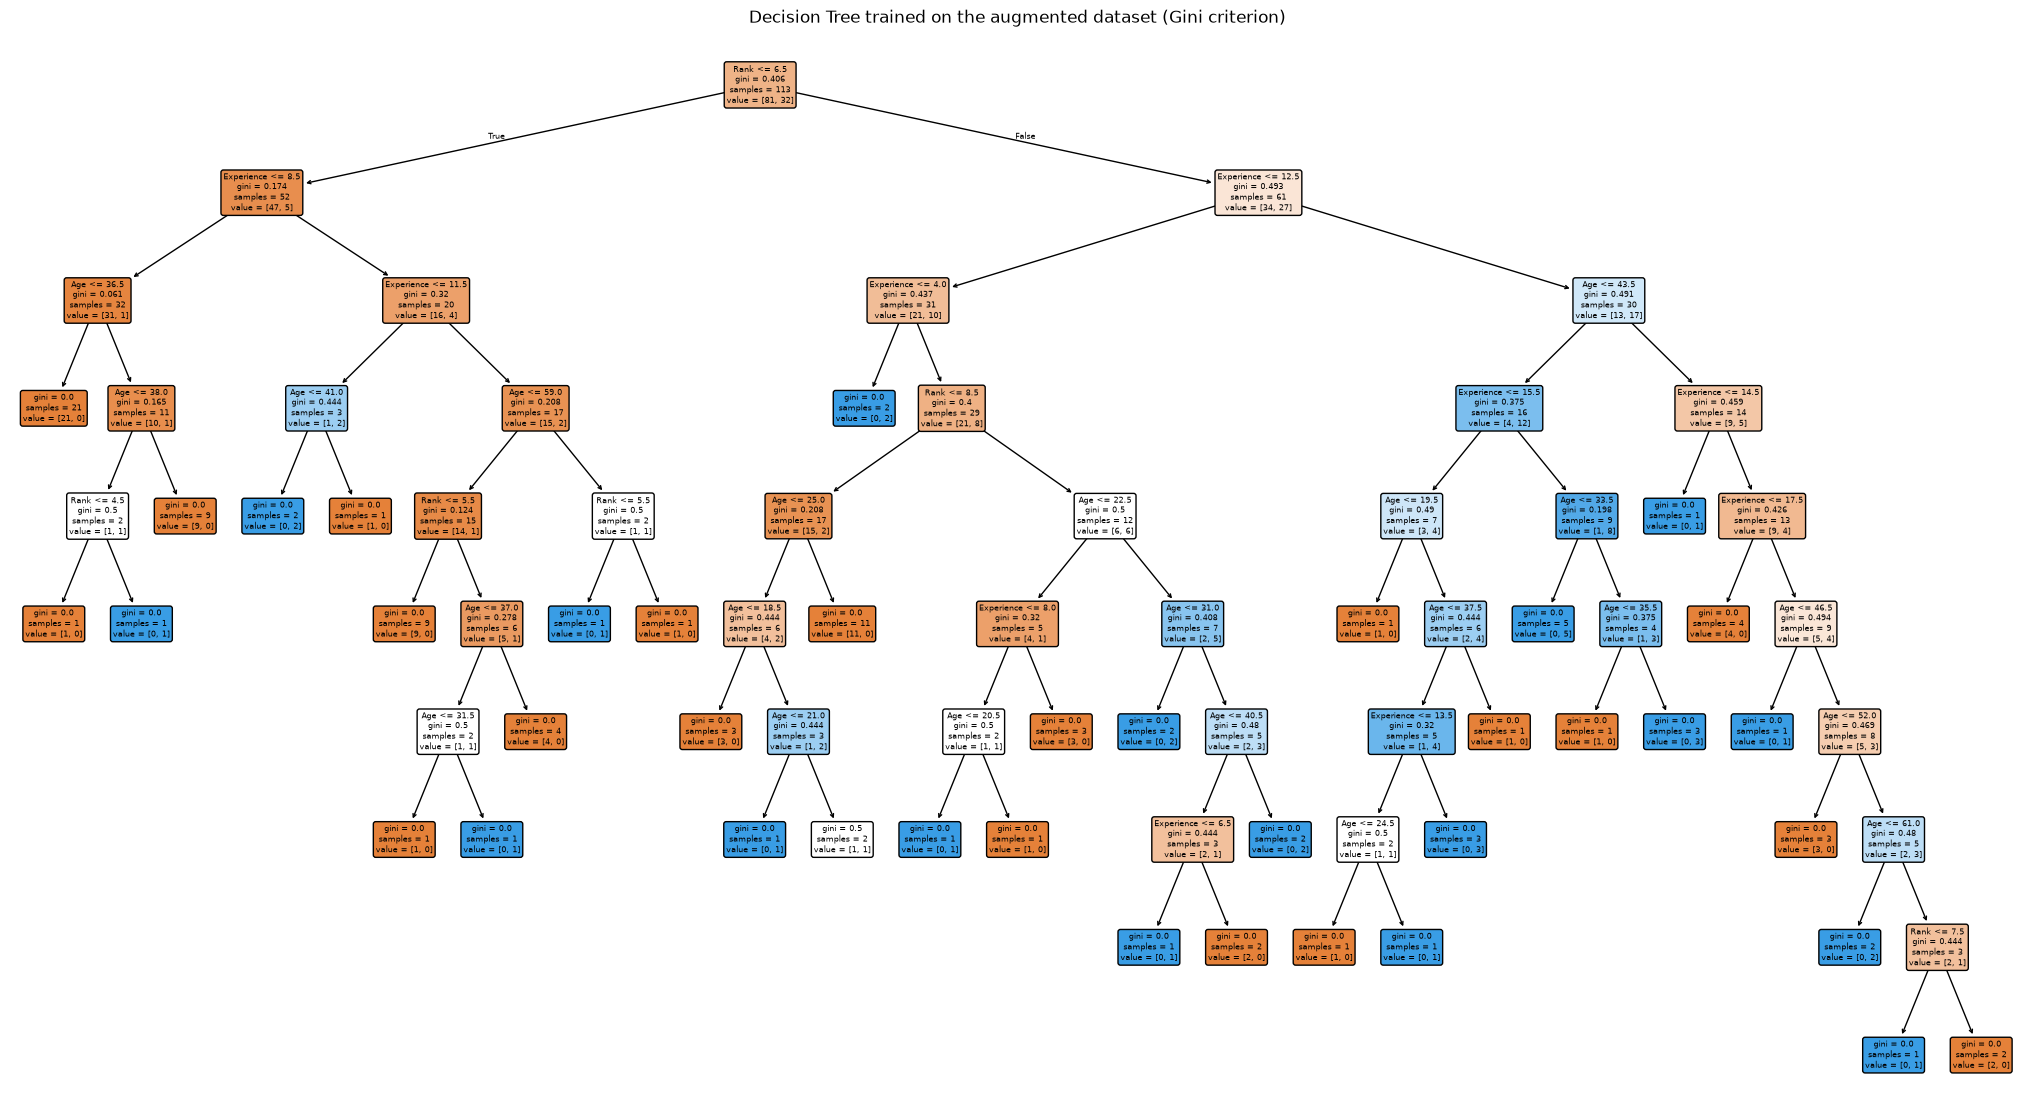

Feature importances (Gini):
           Age: 0.4728
    Experience: 0.2524
          Rank: 0.2747
   Nationality: 0.0000


In [33]:
# Round synthetic numeric columns back to integers.
for column in ["Age", "Experience", "Rank"]:
    df_augmented[column] = df_augmented[column].round().astype(int)

# Same label encoding as section 3, applied to the augmented table.
df_augmented["Nationality"] = df_augmented["Nationality"].map({"UK": 0, "USA": 1, "N": 2})
df_augmented["Go"] = df_augmented["Go"].astype(int)

X_augmented = df_augmented[features]
y_augmented = df_augmented["Go"]

dtree_gini = DecisionTreeClassifier(criterion="gini", random_state=42)
dtree_gini.fit(X_augmented, y_augmented)

plt.figure(figsize=(26, 14))
tree.plot_tree(dtree_gini, feature_names=features, filled=True, rounded=True)
plt.title("Decision Tree trained on the augmented dataset (Gini criterion)")
plt.show()

print("Feature importances (Gini):")
for name, importance in zip(features, dtree_gini.feature_importances_):
    print(f"  {name:>12}: {importance:.4f}")

## Part B — Gini impurity vs entropy


In [36]:
dtree_entropy = DecisionTreeClassifier(criterion="entropy", random_state=42)
dtree_entropy.fit(X_augmented, y_augmented)

structure = pd.DataFrame(
    {
        "Gini tree": [
            dtree_gini.get_depth(),
            dtree_gini.tree_.node_count,
            dtree_gini.get_n_leaves(),
        ],
        "Entropy tree": [
            dtree_entropy.get_depth(),
            dtree_entropy.tree_.node_count,
            dtree_entropy.get_n_leaves(),
        ],
    },
    index=["Tree depth", "Number of nodes", "Number of leaves"],
)
display(structure)

importance_comparison = pd.DataFrame(
    {
        "Feature": features,
        "Gini importance": dtree_gini.feature_importances_,
        "Entropy importance": dtree_entropy.feature_importances_,
    }
)
display(importance_comparison.sort_values("Gini importance", ascending=False).reset_index(drop=True))

,Gini tree,Entropy tree
Tree depth,9,9
Number of nodes,77,77
Number of leaves,39,39


,Feature,Gini importance,Entropy importance
0,Age,0.472825,0.478276
1,Rank,0.274743,0.242867
2,Experience,0.252432,0.278858
3,Nationality,0.000000,0.000000


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(30, 14))

tree.plot_tree(dtree_gini, feature_names=features, filled=True, rounded=True, ax=axes[0])
axes[0].set_title("Gini criterion")

tree.plot_tree(dtree_entropy, feature_names=features, filled=True, rounded=True, ax=axes[1])
axes[1].set_title("Entropy criterion")

fig.suptitle("Augmented dataset: Gini vs entropy Decision Tree", fontsize=18)
plt.tight_layout()
plt.show()

### What is the Gini method and how does it work?

Gini impurity measures how mixed the classes are inside a node: with class probabilities \(p_i\) it
equals \(1 - \sum_i p_i^2\), the probability that a randomly chosen sample would be labelled
incorrectly if it were labelled randomly according to the node's class mix. It is \(0\) for a pure
node and largest when the classes are balanced, and CART grows the tree by repeatedly choosing the
split that most reduces the weighted Gini impurity of the child nodes.

### Differences between the Gini and entropy trees

Entropy, \(H = -\sum_i p_i \log_2 p_i\), penalizes class mixing with a logarithm instead of a square, so the two criteria can rank candidate splits differently and produce trees with a different depth and number of leaves.
Because feature importance is the normalized impurity reduction contributed by each feature, the
importance scores — and sometimes their order — can also differ between the two models.However, as shown in the importance table, for a dataset as small as this one, the trees remain quite similar, as the remaining structure is determined by splits that are essentially tied in terms of their effectiveness